> **Course website copy · Team 4.** This is the team's final submission as handed in, with their run outputs. Names are removed. The one cell below was added for the website: it fetches the team's data files from the course repository, so *Runtime → Run all* works without uploading anything. Everything after it is the team's own work.

In [ ]:
# Added for the course website (not part of the team's submission):
# copy the team's data files from the course repository into the folder the notebook expects.
import os, shutil, subprocess
SRC = "week07/projects/team4-refrigerator/data"
TARGET = "data"
if not os.path.isdir("course_copy"):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse",
                    "https://github.com/TH-Koln-Bartnik/sscm-2026-student", "course_copy"], check=True)
    subprocess.run(["git", "-C", "course_copy", "sparse-checkout", "set", SRC], check=True)
os.makedirs(TARGET, exist_ok=True)
for name in os.listdir(os.path.join("course_copy", SRC)):
    shutil.copy(os.path.join("course_copy", SRC, name), os.path.join(TARGET, name))
print(len(os.listdir(TARGET)), "data files in", os.path.abspath(TARGET))


# Refrigerator line: what happens when the compressor supplier fails?

**Key question:** When our key supplier fails, what happens to units per week, cost per unit and CO₂ per unit, and what should we do about it?

**Product:** Liebherr CNc 5203 fridge-freezer, plant Ochsenhausen (Germany) · **Key component:** hermetic compressor

| Scenario | What happens |
|---|---|
| `baseline` | Normal operation. Compressors come from China (Jiaxipera) by ship via the Suez Canal |
| `disruption` | Red Sea crisis: ships must go around the Cape of Good Hope, so the lead time gets longer and less reliable, and freight gets dearer |
| `countermeasure` | Same disruption, but all compressors come from Slovakia (Embraco) by truck |

Three extra runs are only for comparison (table in section 7 and on the poster, not in the animation):
`compare_safety_stock` (China + 8 extra working days of safety stock in the disruption),
`compare_slovakia_no_disruption` (Slovakia in normal times: why is China our baseline?) and
`compare_compressor_price_x2` (baseline with a compressor twice as expensive).

**How to use this notebook**

1. Run the cells from top to bottom (▶ button or Shift + Enter).
2. In Colab, cell 1 asks you to upload `data.zip` (the folder `data/` with all CSV files).
3. Change numbers only in the CSV files, never in the code. Then run everything again.

**Status:** Final version. Section 8 runs the official check cell unchanged, section 9 writes `results.json` and `animation.html`.

In [1]:
# ===== Cell 1: setup and data =====
import os        # check if a folder exists
import json      # write results.json
import math      # ceil, sqrt
import zipfile   # unpack data.zip
import numpy as np                 # numbers and random numbers
import pandas as pd                # tables
import matplotlib.pyplot as plt    # charts

DATA_DIR = "data"   # folder with all CSV files

# In Colab the folder is not there yet: ask for data.zip and unpack it.
if not os.path.isdir(DATA_DIR):
    try:
        from google.colab import files     # this only exists in Colab
        print("Please upload data.zip (it contains the folder data/ with all CSV files)")
        uploaded = files.upload()
        for name in uploaded:
            zipfile.ZipFile(name).extractall(".")
    except ImportError:
        raise FileNotFoundError("The folder data/ is missing next to this notebook")

# Read every CSV file into a dictionary of tables: D["bom"] is bom.csv, and so on.
FILES = ["products", "bom", "workcenters", "routing", "process_environment", "suppliers", "locations",
         "network_lanes", "freight_rates", "sources", "transport_modes", "transport_emission_factors",
         "emission_factors"]
D = {}
for name in FILES:
    D[name] = pd.read_csv(f"{DATA_DIR}/{name}.csv")
    print(f"{name:28s} {len(D[name]):4d} rows")

products                        1 rows
bom                             8 rows
workcenters                     6 rows
routing                         6 rows
process_environment             6 rows
suppliers                       2 rows
locations                       5 rows
network_lanes                   5 rows
freight_rates                   5 rows
sources                       155 rows
transport_modes                 4 rows
transport_emission_factors      4 rows
emission_factors                4 rows


## 1 · Course values and model choices

The two course values (20 % inventory holding rate, 100 EUR per tonne CO₂e) are the same for every group. The other values are our modelling choices:

- **Time:** the model counts in working minutes. One working day = one shift (8 h = 480 min), one week = 5 working days. Lead times in the data are in working days.
- **Planned output:** we plan the line at 90 % of the bottleneck capacity. At 100 % the queue in front of the bottleneck would grow forever (variability and waiting, Week 2).
- **Ordering rule:** every Monday we order up to a target stock = need during the lead time + one week + safety stock. Safety stock = 1.65 × spread of the lead time × daily need (95 % service level, Week 6).
- **No compressor in stock:** the next refrigerator is not started and the line stands still for that cycle. Lost cycles are not made up later.

In [2]:
# ===== Cell 2: constants =====
WEEKS = 52                     # one year
SEEDS = range(1, 11)           # every scenario runs with the random seeds 1 to 10
HOLDING_RATE = 0.20            # course value: inventory holding cost per year (20 % of the stock value)
CO2_PRICE_EUR_PER_T = 100.0    # course value: EUR per tonne CO2e
PLAN_UTIL = 0.90               # we plan the bottleneck at 90 % of its capacity
Z = 1.65                       # safety factor for a 95 % service level

# Working time, taken from workcenters.csv (all stations work the same shift)
WC = D["workcenters"].set_index("workcenter_id")
DAY_MIN = WC["shift_hours"].iloc[0] * 60          # minutes per working day (8 h = 480 min)
DAYS_PER_WEEK = int(WC["days_per_week"].iloc[0])  # working days per week (5)
WEEK_MIN = DAY_MIN * DAYS_PER_WEEK                # minutes per working week (2400)
T_END = WEEKS * WEEK_MIN                          # the whole year in working minutes

print(f"One working day = {DAY_MIN:.0f} min, one week = {WEEK_MIN:.0f} min, one year = {T_END:,.0f} min")

One working day = 480 min, one week = 2400 min, one year = 124,800 min


In [3]:
# ===== Cell 3: look-ups we need again and again =====
PRODUCT = D["products"].iloc[0]                    # the only row of products.csv
BOM = D["bom"]
SUPPLIERS = D["suppliers"].set_index("supplier_id")

# The key component is the one BOM row with a supplier_id (the compressor)
KEY = BOM[BOM["supplier_id"].notna()].iloc[0]
KEY_QTY = float(KEY["qty_per_unit"])               # compressors per refrigerator (1)
KEY_MASS = float(KEY["mass_kg"])                   # kg per compressor (for transport)

# Material cost of everything except the compressor (the compressor price depends on the supplier)
all_parts = (BOM["unit_cost_eur"] * BOM["qty_per_unit"]).sum()
OTHER_MATERIAL = float(all_parts - KEY["unit_cost_eur"] * KEY_QTY)

# Emission factors and transport tables
EF = D["emission_factors"].set_index("factor_id")
GRID_DE = float(EF.loc["grid_electricity_DE_2024", "value"])          # kg CO2e per kWh in our German plant
G_PER_TKM = D["transport_emission_factors"].set_index("mode_id")["g_co2e_per_tkm"]   # g CO2e per tonne-km
MODES = D["transport_modes"].set_index("mode_id")
LANES = D["network_lanes"].set_index("lane_id")
RATES = D["freight_rates"].set_index("lane_id")

print(f"Key component: {KEY['component_name']}, {KEY_MASS} kg, {KEY_QTY:.0f} per refrigerator")
print(f"Other materials: {OTHER_MATERIAL:.2f} EUR per refrigerator")

Key component: Hermetic compressor (R600a), 7.2 kg, 1 per refrigerator
Other materials: 227.40 EUR per refrigerator


## 2 · The line: capacity and bottleneck

- **Effective minutes per unit** at a station = process time ÷ (number of places × availability).
- The station with the most effective minutes per unit is the **bottleneck**. It sets the pace of the whole line.
- We start one refrigerator every **cycle time** = bottleneck minutes ÷ 90 %.

In [4]:
# ===== Cell 4: build the line =====
# One table with one row per station: routing + workcenters + electricity data
LINE = D["routing"].merge(D["workcenters"], on=["workcenter_id", "seq"])
LINE = LINE.merge(D["process_environment"], on="workcenter_id")
LINE = LINE.sort_values("seq").reset_index(drop=True)

# Effective minutes per refrigerator and capacity per hour of every station
LINE["eff_min_per_unit"] = LINE["process_time_min"] / (LINE["num_servers"] * LINE["availability"])
LINE["capacity_per_hour"] = 60 / LINE["eff_min_per_unit"]

# Bottleneck = station with the largest effective time
BOTTLENECK = LINE.loc[LINE["eff_min_per_unit"].idxmax()]

# Cycle time: we start one refrigerator every TAKT_MIN minutes
TAKT_MIN = BOTTLENECK["eff_min_per_unit"] / PLAN_UTIL
STARTS_PER_DAY = DAY_MIN / TAKT_MIN

# Planned utilization of every station at this pace
LINE["planned_util"] = LINE["eff_min_per_unit"] / TAKT_MIN

# All planned start times of the year, and the same times sorted by week
PLANNED_STARTS = np.arange(0.0, T_END, TAKT_MIN)
N_PLANNED = len(PLANNED_STARTS)
STARTS_BY_WEEK = []
for week in range(WEEKS):
    in_this_week = (PLANNED_STARTS >= week * WEEK_MIN) & (PLANNED_STARTS < (week + 1) * WEEK_MIN)
    STARTS_BY_WEEK.append(PLANNED_STARTS[in_this_week])

print(f"Bottleneck: {BOTTLENECK['workcenter_id']} {BOTTLENECK['workcenter_name']}")
print(f"Cycle time: one refrigerator every {TAKT_MIN:.2f} min = {60 / TAKT_MIN:.1f} per hour "
      f"= {WEEK_MIN / TAKT_MIN:.0f} per week planned")
LINE[["workcenter_id", "workcenter_name", "num_servers", "process_time_min", "availability",
      "capacity_per_hour", "planned_util"]].round(2)

Bottleneck: WC3 Final assembly (compressor, cooling circuit, electronics, doors)
Cycle time: one refrigerator every 2.96 min = 20.2 per hour = 810 per week planned


,workcenter_id,workcenter_name,num_servers,process_time_min,availability,capacity_per_hour,planned_util
0,WC1,"Forming (thermoform inner liner, punch and ben...",1,2.0,0.85,25.5,0.79
1,WC2,Foaming (fill cabinet and doors with PU foam),3,6.0,0.85,25.5,0.79
2,WC3,"Final assembly (compressor, cooling circuit, e...",5,12.0,0.90,22.5,0.90
3,WC4,Refrigerant charging and leak test,2,4.0,0.90,27.0,0.75
4,WC5,"Quality test (test run, thermal camera)",2,4.0,0.95,28.5,0.71
5,WC6,Packaging,1,1.8,0.90,30.0,0.68


## 3 · Scenarios

The disruption copies the Red Sea crisis of 2024: orders placed in weeks 10 to 35 travel around the Cape of Good Hope (`LANE-SHA-RTM-CAPE`). This makes the lead time (43 − 35) × 5/7 ≈ 5.7 working days longer, the spread larger and the freight dearer. Sources: DHL article of 23 Feb 2024 and the Drewry World Container Index (see sources.csv).

Important: the planners keep ordering with the normal lead time from suppliers.csv. This is what really happened in 2024: the plans suddenly no longer fitted.

In [5]:
# ===== Cell 5: scenarios and routes =====
DISRUPTION_WEEKS = range(10, 36)   # orders placed in these weeks go around the Cape (weeks 10 to 35)

# Which lanes an order uses on its way from the supplier to our plant
ROUTES = {
    "SUP-CN":      ["LANE-CN-SHA", "LANE-SHA-RTM", "LANE-RTM-PLANT"],        # China via Suez
    "SUP-CN-CAPE": ["LANE-CN-SHA", "LANE-SHA-RTM-CAPE", "LANE-RTM-PLANT"],   # China around the Cape
    "SUP-SK":      ["LANE-SK-PLANT"],                                        # Slovakia by truck
}

# The two countermeasures we looked at. The team picked ONE for the scoreboard and the animation;
# the other one is only shown as a comparison. To swap them, change this one line.
COUNTERMEASURE = "slovakia"          # "slovakia" or "safety_stock"

OPTIONS = {
    "slovakia":     {"label": "Disruption + compressors from Slovakia by truck",
                     "supplier": "SUP-SK", "disruption": True, "extra_safety_days": 0, "price_factor": 1.0},
    "safety_stock": {"label": "Disruption + 8 days extra safety stock",
                     "supplier": "SUP-CN", "disruption": True, "extra_safety_days": 8, "price_factor": 1.0},
}
OTHER = "safety_stock" if COUNTERMEASURE == "slovakia" else "slovakia"

# The three scenarios of the scoreboard and the animation. Only these settings differ between them.
SCENARIOS = {
    "baseline":       {"label": "Baseline: normal operation, compressors from China",
                       "supplier": "SUP-CN", "disruption": False, "extra_safety_days": 0, "price_factor": 1.0},
    "disruption":     {"label": "Disruption: Red Sea, ships around the Cape",
                       "supplier": "SUP-CN", "disruption": True, "extra_safety_days": 0, "price_factor": 1.0},
    "countermeasure": OPTIONS[COUNTERMEASURE],
}

# Extra runs for comparison only (not in the animation)
COMPARISONS = {
    f"compare_{OTHER}":               OPTIONS[OTHER],
    "compare_slovakia_no_disruption": {"label": "Slovakia in normal times (no disruption)",
                                       "supplier": "SUP-SK", "disruption": False, "extra_safety_days": 0, "price_factor": 1.0},
    "compare_compressor_price_x2":    {"label": "Baseline with a compressor twice as expensive",
                                       "supplier": "SUP-CN", "disruption": False, "extra_safety_days": 0, "price_factor": 2.0},
}
ALL_RUNS = {**SCENARIOS, **COMPARISONS}   # everything we simulate

# How much the Cape route changes the lead time.
# The lanes are in calendar days, the supplier lead time in working days: 5 working days per 7 calendar days.
CAL_TO_WORK = 5 / 7
suez = LANES.loc["LANE-SHA-RTM"]
cape = LANES.loc["LANE-SHA-RTM-CAPE"]
CAPE_EXTRA_DAYS = (cape["transit_days_mean"] - suez["transit_days_mean"]) * CAL_TO_WORK
# Spreads add up as variances (sd squared), not as sd
CAPE_EXTRA_VARIANCE = (cape["transit_days_sd"] ** 2 - suez["transit_days_sd"] ** 2) * CAL_TO_WORK ** 2

print(f"Cape route: +{CAPE_EXTRA_DAYS:.1f} working days lead time, sd grows from "
      f"{SUPPLIERS.loc['SUP-CN', 'lead_time_sd_days']:.1f} to "
      f"{math.sqrt(SUPPLIERS.loc['SUP-CN', 'lead_time_sd_days'] ** 2 + CAPE_EXTRA_VARIANCE):.1f} working days")

Cape route: +5.7 working days lead time, sd grows from 3.5 to 4.5 working days


## 4 · Supply chain: ordering, deliveries, stock

The function goes through the year week by week:

1. Monday morning: deliveries that have arrived go into stock.
2. Monday: we order up to the target stock (the order arrives after a random lead time).
3. Then we go through every planned start of the week. Before each start, deliveries that have arrived go into stock. If a compressor is in stock, the next refrigerator starts. If not, the line stands still for this cycle.

In [6]:
# ===== Cell 6: supply chain =====
def draw_lead_time(rng, mean_days, sd_days, via_cape):
    # One random lead time in working days (normal distribution, at least 1 day).
    variance = sd_days ** 2
    if via_cape:                                   # detour around the Cape: longer and less reliable
        mean_days = mean_days + CAPE_EXTRA_DAYS
        variance = variance + CAPE_EXTRA_VARIANCE
    days = rng.normal(mean_days, math.sqrt(variance))
    return max(1.0, days)


def receive_deliveries(open_orders, received, now, stock):
    # Move every order that has arrived by time `now` into stock.
    for order in list(open_orders):                # list() makes a copy, because we remove items in the loop
        if order["arrival"] <= now:
            stock = stock + order["qty"]
            received.append(order)                 # remember it for transport cost and CO2
            open_orders.remove(order)
    return stock


def simulate_supply(scenario, seed):
    # Simulate one year of ordering and stock. Returns the start times of all refrigerators that could start.
    rng = np.random.default_rng([seed, 1])         # own random numbers for the supply chain

    supplier = SUPPLIERS.loc[scenario["supplier"]]  # one row of suppliers.csv
    lead_mean = supplier["lead_time_mean_days"]     # the planners use this lead time
    lead_sd = supplier["lead_time_sd_days"]

    # --- planning numbers for the ordering rule ---
    need_per_day = STARTS_PER_DAY * KEY_QTY                         # compressors per working day
    need_per_week = need_per_day * DAYS_PER_WEEK
    safety_stock = (Z * lead_sd + scenario["extra_safety_days"]) * need_per_day
    order_up_to = need_per_day * (lead_mean + DAYS_PER_WEEK) + safety_stock
    max_order = supplier["capacity_per_month"] * 12 / WEEKS          # supplier capacity per week
    min_order = supplier["min_per_month"] * 12 / WEEKS               # minimum order per week

    # --- start of the year: as if the system has been running for a long time ---
    # Weekly orders from the last weeks are still on their way.
    open_orders = []
    weeks_on_the_way = math.ceil(lead_mean / DAYS_PER_WEEK)
    for k in range(1, weeks_on_the_way + 1):
        arrival = -k * WEEK_MIN + lead_mean * DAY_MIN               # ordered k weeks ago
        if arrival > 0:                                              # still on its way
            open_orders.append({"arrival": arrival, "qty": need_per_week, "route": scenario["supplier"]})
    # Stock so that stock + on the way + one weekly order = target
    stock = order_up_to - sum(o["qty"] for o in open_orders) - need_per_week

    # --- things we record ---
    started = []                       # start time of every refrigerator that could start
    received = []                      # orders that arrived during the year
    stock_seen = []                    # stock at every planned start (for the average stock)
    stock_monday = np.zeros(WEEKS)     # stock every Monday morning (for the chart)
    lost_starts = np.zeros(WEEKS)      # planned starts lost because no compressor was there
    in_transit_monday = np.zeros(WEEKS)  # compressors on their way, Monday after ordering (for the animation)

    for week in range(WEEKS):
        monday = week * WEEK_MIN

        # 1) Deliveries that have arrived by Monday morning
        stock = receive_deliveries(open_orders, received, monday, stock)
        stock_monday[week] = stock

        # 2) Monday: order up to the target
        on_the_way = sum(o["qty"] for o in open_orders)
        qty = order_up_to - (stock + on_the_way)
        if qty > 0:
            qty = min(qty, max_order)                                # not more than the supplier can make
            qty = max(qty, min_order)                                # not less than the minimum order
            via_cape = scenario["disruption"] and scenario["supplier"] == "SUP-CN" and week in DISRUPTION_WEEKS
            days = draw_lead_time(rng, lead_mean, lead_sd, via_cape)
            route = "SUP-CN-CAPE" if via_cape else scenario["supplier"]
            open_orders.append({"arrival": monday + days * DAY_MIN, "qty": qty, "route": route})
        in_transit_monday[week] = sum(o["qty"] for o in open_orders)

        # 3) Every planned start of this week
        for t in STARTS_BY_WEEK[week]:
            stock = receive_deliveries(open_orders, received, t, stock)
            stock_seen.append(stock)
            if stock >= KEY_QTY:          # compressor in stock: start the refrigerator
                stock = stock - KEY_QTY
                started.append(t)
            else:                         # no compressor: the line stands still for this cycle
                lost_starts[week] += 1

    # Deliveries that arrive after the last start but still inside the year
    receive_deliveries(open_orders, received, T_END, stock)

    return {"started": np.array(started), "received": received, "avg_stock": float(np.mean(stock_seen)),
            "stock_monday": stock_monday, "lost_starts": lost_starts, "in_transit_monday": in_transit_monday,
            "supplier": supplier}

## 5 · The line: every refrigerator through every station

- Every station works first come, first served. A refrigerator starts at a station as soon as it has arrived **and** a place is free.
- Process times vary at random (gamma distribution with the mean and the coefficient of variation from the data).
- Breakdowns are included through the availability: time ÷ availability.
- Every refrigerator gets the same random times in every scenario. So we compare the scenarios fairly.

In [7]:
# ===== Cell 7: the line =====
def simulate_line(start_times, seed):
    # Send every started refrigerator through all stations. Returns finish times and station figures.
    rng = np.random.default_rng([seed, 2])      # own random numbers for the line
    n = len(start_times)
    arrive = np.array(start_times, dtype=float)  # time each refrigerator arrives at the current station
    station_rows = []
    weekly_queue = []                            # per station: average refrigerators waiting in each week

    for _, station in LINE.iterrows():
        places = int(station["num_servers"])
        mean = station["process_time_min"]
        cv = station["process_time_cv"]

        # Gamma distribution with this mean and cv: shape = 1 / cv², scale = mean × cv².
        # We draw one time for every PLANNED start. Refrigerator number i then gets the same time in every scenario.
        times = rng.gamma(1 / cv ** 2, mean * cv ** 2, size=N_PLANNED)[:n]
        times = times / station["availability"]  # breakdowns make every job take longer on average

        free_at = [0.0] * places                 # time at which each place is free again
        begin = np.zeros(n)                      # when work on refrigerator i begins here
        finish = np.zeros(n)                     # when it is done here
        queue_order = np.argsort(arrive, kind="stable")   # first come, first served

        for i in queue_order:
            place = free_at.index(min(free_at))             # the place that is free first
            begin[i] = max(arrive[i], free_at[place])       # wait if this place is still busy
            finish[i] = begin[i] + times[i]
            free_at[place] = finish[i]

        # Figures inside the year only (cut everything at T_END)
        busy_min = (np.minimum(finish, T_END) - np.minimum(begin, T_END)).clip(min=0).sum()
        wait_each = (np.minimum(begin, T_END) - np.minimum(arrive, T_END)).clip(min=0)   # minutes each unit waited
        wait_min = wait_each.sum()
        # Waiting minutes per week (counted in the week the unit arrived) / minutes per week = average queue that week
        waited_per_week = np.histogram(arrive, bins=WEEKS, range=(0, T_END), weights=wait_each)[0]
        weekly_queue.append(waited_per_week / WEEK_MIN)
        working_h = busy_min * station["availability"] / 60       # hours really working (without breakdowns)
        station_rows.append({
            "workcenter_id": station["workcenter_id"],
            "utilization": busy_min / (places * T_END),            # share of the available time the station is busy
            "avg_queue": wait_min / T_END,                         # average number of refrigerators waiting
            "working_h": working_h,
            "idle_h": places * T_END / 60 - working_h,
        })

        arrive = finish     # done here = arrives at the next station

    # weekly_queue as rows = weeks, columns = stations (the order the animation expects)
    return arrive, pd.DataFrame(station_rows), np.array(weekly_queue).T

## 6 · Scoreboard: units, cost, CO₂, stoppage

**Total cost per year** = materials + 52 × station fixed costs + transport + 0.20 × average stock value + 100 EUR/t × t CO₂e

**Cost per unit** = total cost ÷ refrigerators finished in the year

**CO₂ per unit** = making the compressor + electricity in our plant + transport of the compressors

In [8]:
# ===== Cell 8: transport and one complete run =====
def transport_cost_and_co2(received_orders):
    # Freight cost in EUR and transport CO2 in kg for all orders that arrived in the year.
    cost = 0.0
    kg_co2 = 0.0
    for order in received_orders:
        tonnes = order["qty"] * KEY_MASS / 1000
        for lane_id in ROUTES[order["route"]]:
            lane = LANES.loc[lane_id]
            rate = RATES.loc[lane_id]
            capacity_t = MODES.loc[lane["mode_id"], "capacity_kg"] / 1000
            shipments = max(1, math.ceil(tonnes / capacity_t))     # how many trucks or containers
            one = rate["rate_eur_per_shipment"] + rate["rate_eur_per_tkm"] * (tonnes / shipments) * lane["distance_km"]
            one = max(one, rate["min_charge_eur"])                  # at least the minimum charge
            cost = cost + shipments * one
            kg_co2 = kg_co2 + tonnes * lane["distance_km"] * G_PER_TKM[lane["mode_id"]] / 1000   # g -> kg
    return cost, kg_co2


def run_one(scenario_name, seed):
    # Run one scenario with one seed and fill the scoreboard.
    scenario = ALL_RUNS[scenario_name]
    supply = simulate_supply(scenario, seed)
    finish, stations, weekly_queue = simulate_line(supply["started"], seed)
    supplier = supply["supplier"]
    key_price = supplier["unit_price_eur"] * scenario["price_factor"]   # price_factor is 2 only in the price test
    started = supply["started"]

    # --- units ---
    done = finish <= T_END                      # True for every refrigerator finished inside the year
    units = int(done.sum())
    key_used = units * KEY_QTY                  # compressors built into finished refrigerators

    # --- electricity in our plant ---
    st = stations.merge(LINE[["workcenter_id", "kw_running", "kw_idle", "num_servers", "fixed_cost_eur_week"]])
    kwh = float((st["working_h"] * st["kw_running"] + st["idle_h"] * st["kw_idle"]).sum())

    # --- CO2 in kg ---
    freight_eur, kg_transport = transport_cost_and_co2(supply["received"])
    kg_key = key_used * supplier["kg_co2e_per_unit"]
    kg_power = kwh * GRID_DE
    t_co2 = (kg_key + kg_power + kg_transport) / 1000

    # --- cost in EUR (course formula) ---
    materials = units * (OTHER_MATERIAL + KEY_QTY * key_price)
    fixed = WEEKS * float((st["num_servers"] * st["fixed_cost_eur_week"]).sum())
    holding = HOLDING_RATE * supply["avg_stock"] * key_price
    co2_cost = CO2_PRICE_EUR_PER_T * t_co2
    total = materials + fixed + freight_eur + holding + co2_cost

    # --- Little's Law: parts on the line = units per hour × hours on the line ---
    time_on_line = np.minimum(finish, T_END) - started               # minutes inside the year
    wip = float(time_on_line.clip(min=0).sum() / T_END)              # average refrigerators on the line
    units_per_hour = units / (T_END / 60)
    hours_on_line = float((finish[done] - started[done]).mean() / 60)

    return {
        "scenario": scenario_name, "seed": seed,
        # the four scoreboard numbers
        "units_per_week": units / WEEKS,
        "cost_per_unit_eur": total / units,
        "kg_co2e_per_unit": t_co2 * 1000 / units,
        "hours_stopped": float(supply["lost_starts"].sum() * TAKT_MIN / 60),
        # details for the poster and the checks
        "units_started": len(started), "units_finished": units, "key_used": key_used,
        "cost_materials": materials, "cost_fixed": fixed, "cost_transport": freight_eur,
        "cost_holding": holding, "cost_co2": co2_cost,
        "kg_co2e_key": kg_key / units, "kg_co2e_power": kg_power / units, "kg_co2e_transport": kg_transport / units,
        "kwh_per_unit": kwh / units, "avg_key_stock": supply["avg_stock"],
        "wip": wip, "units_per_hour": units_per_hour, "hours_on_line": hours_on_line,
        "max_utilization": float(st["utilization"].max()),
        # weekly series for the charts and the animation
        "stations": st,
        "weekly_units": np.histogram(finish[done], bins=WEEKS, range=(0, T_END))[0],
        "weekly_stock": supply["stock_monday"],
        "weekly_stop_h": supply["lost_starts"] * TAKT_MIN / 60,
        "weekly_in_transit": supply["in_transit_monday"],
        "weekly_queue": weekly_queue,
    }

## 7 · All scenarios with seeds 1 to 10

The first three columns are the scoreboard. The `compare_` columns are extra runs for the poster. Takes about a minute in Colab.

In [9]:
# ===== Cell 9: run everything =====
RUNS = {}                                  # RUNS["baseline"] = list of 10 results, one per seed
for name in ALL_RUNS:
    RUNS[name] = []
    for seed in SEEDS:
        RUNS[name].append(run_one(name, seed))
    print(f"{name:32s} done")

SCORE = ["units_per_week", "cost_per_unit_eur", "kg_co2e_per_unit", "hours_stopped"]

# Scoreboard table: mean [lowest, highest] over the 10 seeds
table = {}
for name in ALL_RUNS:
    column = {}
    for metric in SCORE:
        values = [r[metric] for r in RUNS[name]]
        column[metric] = f"{np.mean(values):,.2f} [{np.min(values):,.2f}, {np.max(values):,.2f}]"
    table[name] = column
pd.DataFrame(table)

baseline                         done
disruption                       done
countermeasure                   done
compare_safety_stock             done
compare_slovakia_no_disruption   done
compare_compressor_price_x2      done


,baseline,disruption,countermeasure,compare_safety_stock,compare_slovakia_no_disruption,compare_compressor_price_x2
units_per_week,"808.05 [800.75, 809.79]","781.38 [769.88, 791.08]","807.36 [804.65, 809.44]","808.66 [803.52, 809.79]","807.36 [804.65, 809.44]","808.05 [800.75, 809.79]"
cost_per_unit_eur,"292.88 [292.74, 293.28]","295.97 [295.30, 296.72]","294.00 [293.90, 294.16]","294.29 [294.19, 294.57]","294.00 [293.90, 294.16]","307.12 [306.98, 307.52]"
kg_co2e_per_unit,"21.30 [21.28, 21.33]","21.67 [21.64, 21.72]","16.86 [16.85, 16.87]","21.64 [21.63, 21.68]","16.86 [16.85, 16.87]","21.30 [21.28, 21.33]"
hours_stopped,"4.40 [0.00, 23.16]","72.93 [48.05, 102.42]","6.19 [0.74, 13.19]","2.84 [0.00, 16.05]","6.19 [0.74, 13.19]","4.40 [0.00, 23.16]"


In [10]:
# ===== Cell 10: what one refrigerator costs and emits (mean over the seeds) =====
parts = ["cost_materials", "cost_fixed", "cost_transport", "cost_holding", "cost_co2"]
split = {}
for name in ALL_RUNS:
    split[name] = {}
    for p in parts:
        split[name][p] = np.mean([r[p] / r["units_finished"] for r in RUNS[name]])     # EUR per unit
    split[name]["= cost_per_unit"] = sum(split[name][p] for p in parts)
    for p in ["kg_co2e_key", "kg_co2e_power", "kg_co2e_transport"]:
        split[name][p] = np.mean([r[p] for r in RUNS[name]])                         # kg per unit
pd.DataFrame(split).round(2)

,baseline,disruption,countermeasure,compare_safety_stock,compare_slovakia_no_disruption,compare_compressor_price_x2
cost_materials,241.55,241.55,247.04,241.55,247.04,255.70
cost_fixed,44.33,45.85,44.37,44.30,44.37,44.33
cost_transport,4.78,6.33,0.84,6.13,0.84,4.78
cost_holding,0.09,0.08,0.08,0.15,0.08,0.18
cost_co2,2.13,2.17,1.69,2.16,1.69,2.13
= cost_per_unit,292.88,295.97,294.00,294.29,294.00,307.12
kg_co2e_key,16.50,16.50,14.30,16.50,14.30,16.50
kg_co2e_power,2.14,2.17,2.14,2.14,2.14,2.14
kg_co2e_transport,2.66,3.00,0.42,3.00,0.42,2.66


## 8 · Official check cell

The check cell from the course (v1.0, course GitHub `week04/project/project_check_cell.py`) is pasted below **unchanged**.
It needs two names: `DATA_DIR` (we set it in cell 1) and `baseline`, a list with one dictionary per seed and eight fixed keys.
Our results use other names, so the cell just before it copies our numbers into these eight keys.

In [11]:
# ===== Cell 11: hand our baseline results to the official check cell =====
# The check cell expects these eight keys. We only rename our own numbers, nothing is recalculated.
baseline = []
for r in RUNS["baseline"]:                          # one dictionary per seed (10 in total)
    baseline.append({
        "weeks_simulated": WEEKS,                   # 52 weeks
        "hours_simulated": T_END / 60,              # working hours of the year (same clock as hours_on_line)
        "units_started": r["units_started"],        # refrigerators that entered the line
        "units_finished": r["units_finished"],      # refrigerators finished inside the year
        "key_components_used": r["key_used"],       # compressors built into finished refrigerators
        "avg_units_on_line": r["wip"],              # average refrigerators on the line (L in Little's Law)
        "avg_hours_on_line": r["hours_on_line"],    # average hours from start to finish (W in Little's Law)
        "cost_per_unit_eur": r["cost_per_unit_eur"],
    })
print(f"baseline ready: {len(baseline)} runs")

baseline ready: 10 runs


In [12]:
# ===================== SSCM 2026 · GROUP PROJECT CHECK CELL · v1.0 =====================
# Copy this cell into your notebook UNCHANGED and run it after your baseline run.
# It needs two names defined earlier in your notebook:
#   DATA_DIR = the folder that holds your CSV files, e.g. DATA_DIR = "my_product_data"
#   baseline = your baseline results: one dictionary per seed (a list of 10), or one
#              dictionary with the means over the seeds. Keys (all numbers):
#     weeks_simulated      weeks in the run (52)
#     hours_simulated      clock hours of the run; the same clock as avg_hours_on_line
#     units_started        units that entered the line
#     units_finished       units that left the last station
#     key_components_used  key components taken from stock into the line
#     avg_units_on_line    time-average of units between start and finish
#     avg_hours_on_line    average hours from start to finish of a finished unit
#     cost_per_unit_eur    one-year total cost divided by units finished
# The grader runs the original of this cell on your files. Do not edit it.
import hashlib, math, os, datetime
import pandas as pd

CHECK_VERSION = "1.0"
REQUIRED = {
    "products.csv": ["product_id", "product_name", "frame_material", "mass_kg", "list_price_eur"],
    "bom.csv": ["product_id", "component_id", "component_name", "qty_per_unit", "mass_kg",
                "unit_cost_eur", "supplier_id", "added_at_workcenter"],
    "workcenters.csv": ["workcenter_id", "workcenter_name", "seq", "num_servers", "shift_hours",
                        "days_per_week", "availability", "process_time_cv", "fixed_cost_eur_week"],
    "routing.csv": ["product_id", "seq", "workcenter_id", "process_time_min", "setup_time_min"],
    "process_environment.csv": ["workcenter_id", "kw_running", "kw_idle", "waste_kg_per_unit",
                                "water_l_per_unit"],
    "suppliers.csv": ["supplier_id", "supplier_name", "country", "component_id", "unit_price_eur",
                      "promised_lead_days", "lead_time_mean_days", "lead_time_sd_days",
                      "capacity_per_month", "min_per_month", "kg_co2e_per_unit", "location_id"],
    "locations.csv": ["location_id", "name", "type", "country", "lat", "lon"],
    "network_lanes.csv": ["lane_id", "origin_id", "destination_id", "mode_id", "distance_km",
                          "transit_days_mean", "transit_days_sd"],
    "freight_rates.csv": ["lane_id", "mode_id", "rate_eur_per_shipment", "rate_eur_per_tkm",
                          "min_charge_eur"],
    "sources.csv": ["file", "row_id", "column", "value", "source_type", "source_or_calculation",
                    "sanity_check"],
}
MAY_BE_BLANK = {("bom.csv", "supplier_id")}           # parts not bought from a modelled supplier
MAY_BE_NEGATIVE = {("locations.csv", "lat"), ("locations.csv", "lon")}
KEYS = ["weeks_simulated", "hours_simulated", "units_started", "units_finished",
        "key_components_used", "avg_units_on_line", "avg_hours_on_line", "cost_per_unit_eur"]

def _cell_fingerprint():
    try:
        return hashlib.sha256(get_ipython().user_ns["_ih"][-1].strip().encode()).hexdigest()[:12]
    except Exception:
        return "n/a"

def _runs():
    b = globals().get("baseline")
    runs = b if isinstance(b, (list, tuple)) else [b]
    if b is None or not runs:
        raise ValueError("no `baseline` defined: run your baseline first")
    for i, r in enumerate(runs, 1):
        missing = [k for k in KEYS if k not in r]
        if missing:
            raise ValueError(f"baseline run {i} lacks {missing}")
        for k in KEYS:
            if not isinstance(r[k], (int, float)) or not math.isfinite(r[k]) or r[k] < 0:
                raise ValueError(f"baseline run {i}: {k} = {r[k]!r} is not a number ≥ 0")
        if r["units_finished"] <= 0 or r["hours_simulated"] <= 0 or r["weeks_simulated"] <= 0:
            raise ValueError(f"baseline run {i}: units_finished, hours and weeks must be > 0")
    return runs

def _verdict(name, ok, lines):
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
    for line in lines:
        print("      " + line)
    return ok

data, results = {}, {}
folder = globals().get("DATA_DIR", ".")
h = hashlib.sha256()

# ---- T1 Format ----------------------------------------------------------------------
problems = []
for fname, cols in REQUIRED.items():
    path = os.path.join(folder, fname)
    if not os.path.exists(path):
        problems.append(f"{fname}: file missing in {folder!r}")
        continue
    h.update(open(path, "rb").read())
    df = pd.read_csv(path)
    df.columns = [str(c) for c in df.columns]
    data[fname] = df
    lacking = [c for c in cols if c not in df.columns]
    if lacking:
        problems.append(f"{fname}: column(s) missing or misspelt: {lacking}")
    if len(df) == 0:
        problems.append(f"{fname}: no rows")
    for c in [c for c in cols if c in df.columns]:
        blanks = df[c].isna() | (df[c].astype(str).str.strip() == "")
        if blanks.any() and (fname, c) not in MAY_BE_BLANK:
            problems.append(f"{fname}: {c} is empty in row(s) {list(df.index[blanks] + 2)}")
        num = pd.to_numeric(df[c], errors="coerce")
        if (num < 0).any() and (fname, c) not in MAY_BE_NEGATIVE:
            problems.append(f"{fname}: {c} is negative in row(s) {list(df.index[num < 0] + 2)}")
if "workcenters.csv" in data and "availability" in data["workcenters.csv"]:
    av = pd.to_numeric(data["workcenters.csv"]["availability"], errors="coerce")
    if ((av <= 0) | (av > 1) | av.isna()).any():
        problems.append("workcenters.csv: availability must be a share between 0 and 1")
if "routing.csv" in data and "process_time_min" in data["routing.csv"]:
    if (pd.to_numeric(data["routing.csv"]["process_time_min"], errors="coerce") <= 0).any():
        problems.append("routing.csv: every process_time_min must be above 0")
results["T1"] = _verdict("T1 Format", not problems,
                         problems[:12] + (["… and more"] if len(problems) > 12 else [])
                         or ["all 10 files present, columns exact, no blanks or negatives"])

# ---- baseline numbers for T2–T5 -------------------------------------------------------
try:
    runs = _runs()
    base_error = None
except Exception as e:
    runs, base_error = [], str(e)
if base_error:
    for t in ["T2 Capacity", "T3 Little's Law", "T4 Flow balance", "T5 Margin"]:
        results[t[:2]] = _verdict(t, False, [base_error])
else:
    try:
        prod = data["products.csv"].iloc[0]
        pid = prod["product_id"]
        wc = data["workcenters.csv"].set_index("workcenter_id")
        rt = data["routing.csv"]
        rt = rt[rt["product_id"] == pid]
        minutes = rt.groupby("workcenter_id")["process_time_min"].sum()
        unknown = [w for w in minutes.index if w not in wc.index]
        avail_min_week = (wc["num_servers"] * wc["shift_hours"] * 60 * wc["days_per_week"]
                          * wc["availability"])
        # ---- T2 Capacity: load offered by the units started, per station
        lines, ok = [], not unknown and len(minutes) > 0
        if unknown:
            lines.append(f"routing.csv names stations not in workcenters.csv: {unknown}")
        worst = {}
        for r in runs:
            for w, m in minutes.items():
                if w in wc.index:
                    share = r["units_started"] * m / (avail_min_week[w] * r["weeks_simulated"])
                    worst[w] = max(worst.get(w, 0), share)
        for w, share in worst.items():
            flag = "  <- 100 % or more" if share >= 1 else ""
            lines.append(f"{w} {wc.loc[w, 'workcenter_name']}: busy {share:.1%} of available time{flag}")
            ok = ok and share < 1
        results["T2"] = _verdict("T2 Capacity", ok, lines)
        # ---- T3 Little's Law: L = λ × W, within 10 %
        lines, ok = [], True
        for i, r in enumerate(runs, 1):
            lam = r["units_finished"] / r["hours_simulated"]
            lw = lam * r["avg_hours_on_line"]
            gap = abs(r["avg_units_on_line"] - lw) / lw if lw > 0 else float("inf")
            ok = ok and gap <= 0.10
            if (gap > 0.10 and len(lines) < 3) or i == 1:
                lines.append(f"run {i}: L = {r['avg_units_on_line']:.2f}  vs  λ×W = {lam:.3f}/h × "
                             f"{r['avg_hours_on_line']:.2f} h = {lw:.2f}  (gap {gap:.1%})")
        results["T3"] = _verdict("T3 Little's Law", ok, lines + [f"{len(runs)} run(s) checked"])
        # ---- T4 Flow balance
        bom = data["bom.csv"]
        bom = bom[bom["product_id"] == pid]
        keys = bom[bom["component_id"].isin(data["suppliers.csv"]["component_id"])]
        lines, ok = [], len(keys) == 1
        if len(keys) != 1:
            lines.append(f"expected one key component (in bom.csv and suppliers.csv), found {len(keys)}")
        else:
            q = float(keys["qty_per_unit"].iloc[0])
            n_opt = int((data["suppliers.csv"]["component_id"] == keys["component_id"].iloc[0]).sum())
            if n_opt < 2:
                lines.append(f"note: only {n_opt} sourcing option in suppliers.csv (the brief asks for two)")
            for i, r in enumerate(runs, 1):
                s, f, u = r["units_started"], r["units_finished"], r["key_components_used"]
                good = f <= s + 0.5 and f * q - 0.5 <= u <= s * q + 0.5
                ok = ok and good
                if not good or i == 1:
                    lines.append(f"run {i}: started {s:,.0f}, finished {f:,.0f}, key components used "
                                 f"{u:,.0f} (allowed {f*q:,.0f} to {s*q:,.0f})")
        results["T4"] = _verdict("T4 Flow balance", ok, lines)
        # ---- T5 Margin
        price = float(prod["list_price_eur"])
        material = float((bom["qty_per_unit"] * bom["unit_cost_eur"]).sum())
        costs = [r["cost_per_unit_eur"] for r in runs]
        lines = [f"cost per unit {min(costs):,.2f} to {max(costs):,.2f} EUR vs list price {price:,.2f} EUR"]
        if min(costs) < material:
            lines.append(f"warning: below the material cost alone ({material:,.2f} EUR per unit)")
        results["T5"] = _verdict("T5 Margin", max(costs) < price, lines)
    except Exception as e:
        for t in ["T2 Capacity", "T3 Little's Law", "T4 Flow balance", "T5 Margin"]:
            if t[:2] not in results:
                results[t[:2]] = _verdict(t, False, [f"could not run: {e}"])

print("-" * 78)
print(f"{sum(results.values())} of 5 tests passed  ·  {'ALL PASS' if all(results.values()) and len(results) == 5 else 'NOT YET'}")
print(f"check cell v{CHECK_VERSION} · cell {_cell_fingerprint()} · data {h.hexdigest()[:12]} · "
      f"{datetime.datetime.now():%Y-%m-%d %H:%M}")
# ======================= end of check cell · do not edit above ==========================

PASS  T1 Format
      all 10 files present, columns exact, no blanks or negatives
PASS  T2 Capacity
      WC1 Forming (thermoform inner liner, punch and bend sheet metal): busy 79.4% of available time
      WC2 Foaming (fill cabinet and doors with PU foam): busy 79.4% of available time
      WC3 Final assembly (compressor, cooling circuit, electronics, doors): busy 90.0% of available time
      WC4 Refrigerant charging and leak test: busy 75.0% of available time
      WC5 Quality test (test run, thermal camera): busy 71.1% of available time
      WC6 Packaging: busy 67.5% of available time
PASS  T3 Little's Law
      run 1: L = 12.40  vs  λ×W = 20.114/h × 0.62 h = 12.40  (gap 0.0%)
      10 run(s) checked
PASS  T4 Flow balance
      run 1: started 41,850, finished 41,837, key components used 41,837 (allowed 41,837 to 41,850)
PASS  T5 Margin
      cost per unit 292.74 to 293.28 EUR vs list price 713.45 EUR
------------------------------------------------------------------------------
5 

## 9 · results.json and the animation

`results.json` is written in the format of the course template (`week04/project/animation_template.html`).
As the course demo recommends, `weeks` shows one representative seed (seed 1) and `scoreboard` the mean over the 10 seeds.
The queue per station is the average number of refrigerators waiting in that week.

In [13]:
# ===== Cell 12: write results.json in the template format =====
def round_list(values, digits):
    return [round(float(v), digits) for v in values]

results = {
    "product": "Liebherr CNc 5203 fridge-freezer",
    "unit": "refrigerators",
    "key_component": "compressors",
    "supplier": "Jiaxipera / Embraco",          # China in baseline and disruption, Slovakia in the countermeasure
    "transport": "ship + truck / truck",
    "stations": ["Forming", "Foaming", "Final assembly", "Refrigerant charging", "Quality test", "Packaging"],
    "scenarios": {},
}
for name in SCENARIOS:                        # only the three scoreboard scenarios
    runs = RUNS[name]
    seed1 = runs[0]                           # seed 1 for the week-by-week film
    results["scenarios"][name] = {
        "label": SCENARIOS[name]["label"],
        "scoreboard": {k: round(float(np.mean([r[k] for r in runs])), 2) for k in SCORE},   # mean of 10 seeds
        "weeks": {
            "queue": [round_list(week, 2) for week in seed1["weekly_queue"]],   # one list per week, one number per station
            "in_transit": round_list(seed1["weekly_in_transit"], 0),
            "stock": round_list(seed1["weekly_stock"], 0),
            "finished": [int(v) for v in seed1["weekly_units"]],
            "stopped_hours": round_list(seed1["weekly_stop_h"], 2),
        },
    }

# The comparison runs go into their own block; the template does not read it
results["comparisons"] = {name: {"label": ALL_RUNS[name]["label"],
                                 "scoreboard": {k: round(float(np.mean([r[k] for r in RUNS[name]])), 2) for k in SCORE}}
                          for name in COMPARISONS}

with open("results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=1)

# Check: the queue must build at the bottleneck (rubric part C)
queue_mean = np.mean(results["scenarios"]["baseline"]["weeks"]["queue"], axis=0)
print("results.json written. Average queue per station (baseline, seed 1):",
      {s: round(float(q), 2) for s, q in zip(results["stations"], queue_mean)})
print("Longest queue at:", results["stations"][int(queue_mean.argmax())])

results.json written. Average queue per station (baseline, seed 1): {'Forming': 0.0, 'Foaming': 0.02, 'Final assembly': 0.42, 'Refrigerant charging': 0.31, 'Quality test': 0.22, 'Packaging': 0.23}
Longest queue at: Final assembly


In [14]:
# ===== Cell 13: animation.html from the course template =====
from IPython.display import HTML, display

TEMPLATE = "sscm-2026-student/week04/project/animation_template.html"
if not os.path.exists(TEMPLATE):                 # in Colab: download the course folder once
    os.system("git clone -q https://github.com/TH-Koln-Bartnik/sscm-2026-student")

template = open(TEMPLATE, encoding="utf-8").read()
page = template.replace("/*RESULTS_JSON*/null", json.dumps(results))   # the template's placeholder for our numbers
with open("animation.html", "w", encoding="utf-8") as f:
    f.write(page)
print("animation.html written: download it from the file panel on the left")
display(HTML(page))

animation.html written: download it from the file panel on the left
<HTML display skipped>


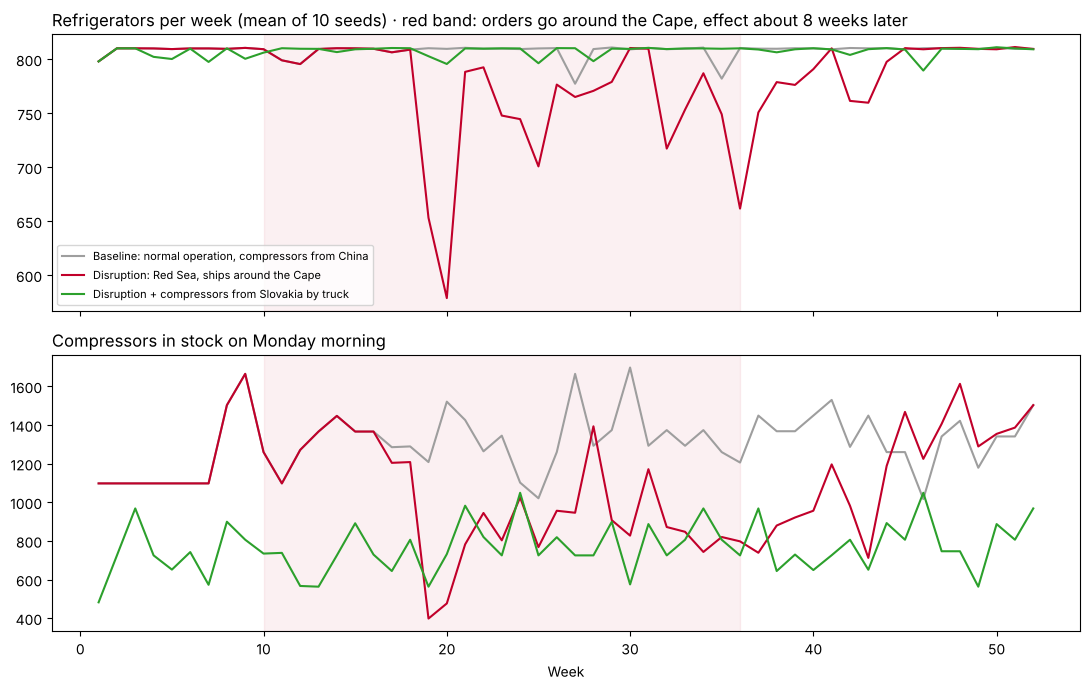

In [15]:
# ===== Cell 14: charts (mean of 10 seeds) =====
COLORS = {"baseline": "#9e9e9e", "disruption": "#c1002a", "countermeasure": "#2ca02c"}
weeks = np.arange(1, WEEKS + 1)
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for name in SCENARIOS:
    label = SCENARIOS[name]["label"]
    top.plot(weeks, np.mean([r["weekly_units"] for r in RUNS[name]], axis=0), label=label, color=COLORS[name])
    bottom.plot(weeks, np.mean([r["weekly_stock"] for r in RUNS[name]], axis=0), label=label, color=COLORS[name])

for ax in (top, bottom):   # light red band = weeks in which orders go around the Cape
    ax.axvspan(min(DISRUPTION_WEEKS), max(DISRUPTION_WEEKS) + 1, color="#c1002a", alpha=0.06)

top.set_title("Refrigerators per week (mean of 10 seeds) · red band: orders go around the Cape, "
              "effect about 8 weeks later", loc="left")
bottom.set_title("Compressors in stock on Monday morning", loc="left")
bottom.set_xlabel("Week")
top.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()